## Multi-Variable Leiden Clustering

In [1]:
import trenchripper as tr

import dask
import warnings
import copy
import random
import re
import umap
import scipy.stats
import anndata

import numpy as np
import pandas as pd
import seaborn as sns
import scipy as sp
import sklearn as skl
import dask.array as da
import scanpy as sc

from tslearn.metrics import cdist_soft_dtw_normalized,cdist_soft_dtw,soft_dtw_alignment
from sklearn.metrics import silhouette_score

from matplotlib import pyplot as plt

random.seed(42)
np.random.seed(42)

dask_wd = '/home/lag36/scratch/lag36/dask/'

warnings.filterwarnings(action='once',category=UserWarning)

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
def parallel_norm_soft_dtw(X,chunk_size=200):
    X_dask = da.from_array(X,chunks=(chunk_size,X.shape[1],X.shape[2]))
    soft_dtw_arr = da.blockwise(cdist_soft_dtw,"ik",X_dask,"itd",X_dask,"ktd",concatenate=True).compute()
    d_ii = np.diag(soft_dtw_arr)
    norm_soft_dtw_arr = soft_dtw_arr - (.5 * (d_ii.reshape((-1, 1)) + d_ii.reshape((1, -1))))
    return norm_soft_dtw_arr

def norm_soft_dtw(X):
    soft_dtw_arr = cdist_soft_dtw(X)
    d_ii = np.diag(soft_dtw_arr)
    norm_soft_dtw_arr = soft_dtw_arr - (.5 * (d_ii.reshape((-1, 1)) + d_ii.reshape((1, -1))))
    return norm_soft_dtw_arr

def inter_exp_distances(x_chunk,exp_ids=[1,2]):
    exp_chunk_arr = []
    mean_exp_dist_dict = {}
    
    exp_chunk_lens = [len(x_chunk[x_chunk['Experiment #']==i]) for i in exp_ids]
    
    if np.all([chunk_len>1 for chunk_len in exp_chunk_lens]):

        for i in exp_ids:
            exp_chunk_arr.append(np.swapaxes(np.stack(x_chunk[x_chunk['Experiment #']==i]['Feature Vector'].values),1,2))

        exp_chunk_lens = [len(exp_chunk) for exp_chunk in exp_chunk_arr]
        exp_chunk_intervals = np.concatenate([np.array([0]),np.add.accumulate(exp_chunk_lens)])

        if np.all([chunk_len>1 for chunk_len in exp_chunk_lens]):
            exp_chunk_arr = np.concatenate(exp_chunk_arr)

            dist_out = norm_soft_dtw(exp_chunk_arr)

            for i in range(len(exp_ids)):
                for j in range(i,len(exp_ids)):
                    dist_section = dist_out[exp_chunk_intervals[i]:exp_chunk_intervals[i+1],exp_chunk_intervals[j]:exp_chunk_intervals[j+1]]
                    if i == j:
                        dist_section = np.trim_zeros(np.sort(np.triu(dist_section).flatten()))
                    else:
                        dist_section = dist_section.flatten()
                    mean_exp_dist_dict[(exp_ids[i],exp_ids[j])] = np.mean(dist_section)

    else:
        for i in range(len(exp_ids)):
            for j in range(i,len(exp_ids)):
                mean_exp_dist_dict[(exp_ids[i],exp_ids[j])] = np.NaN
    
    return mean_exp_dist_dict


def search_go(ns2assoc, obodag, inv_gene_to_id, go_term):
    namespace_abbv = {"biological_process":"BP","molecular_function":"MF","cellular_component":"CC"}
    
    print("Searching for " + str(obodag[go_term].name))
    namespace = namespace_abbv[obodag[go_term].namespace]
    child_goterms = list(obodag[go_term].get_all_children())
    gene_list = [inv_gene_to_id[key] for key,val in ns2assoc[namespace].items() if go_term in val]
    for child_goterm in child_goterms:    
        gene_list += [inv_gene_to_id[key] for key,val in ns2assoc[namespace].items() if child_goterm in val]
    gene_list = sorted(list(set(gene_list)))
    return gene_list

def selection_fn(item, gene_name):
    is_gene = item["Gene"]==gene_name
    if is_gene:
        return item["TargetID"]
    else:
        return 0

def highlight_gene_group(an_df,selection_list):

    highlight_genes_df = copy.deepcopy(an_df)
    
    selection_list = sorted(list(set(highlight_genes_df.obs["Gene"].unique().tolist())&set(selection_list)))

    for i,selected_gene in enumerate(selection_list):
        selected_series = (highlight_genes_df.obs["Gene"]==selected_gene).astype("category")
        selected_series = selected_series.cat.reorder_categories([True,False])
        highlight_genes_df.obs["Selected Genes: " + str(i)] = selected_series
            
    selected_series = (highlight_genes_df.obs["Gene"].isin(selection_list)).astype("category")
    selected_series = selected_series.cat.reorder_categories([True,False])
    highlight_genes_df.obs["All Genes"] = selected_series

    # selected_series = (paga_df.obs["Gene"]=="ftsZ").astype(float)
    # selected_series[selected_series==0.] = np.NaN
    # paga_df.obs["Selected Genes"] = selected_series

    fig = sc.pl.umap(highlight_genes_df, title=selection_list + ["All Genes"], color=["Selected Genes: " + str(i) for i in range(len(selection_list))] + ["All Genes"],
                     groups=[True], show=False, legend_loc='right margin', add_outline=False, size=50, return_fig=True,
                     palette = {True:"red",False:"lightgrey"})# palette ={}

    return fig

def highlight_sgrnas(an_df,selection_list):

    highlight_genes_df = copy.deepcopy(an_df)
    highlight_genes_df.obs["tempindex"] = highlight_genes_df.obs.index
    
    selection_list = sorted(list(set(highlight_genes_df.obs["tempindex"].unique().tolist())&set(selection_list)))        
    selected_series = (highlight_genes_df.obs["tempindex"].isin(selection_list)).astype("category")
    selected_series = selected_series.cat.reorder_categories([True,False])
    highlight_genes_df.obs["All sgRNAs"] = selected_series

    # selected_series = (paga_df.obs["Gene"]=="ftsZ").astype(float)
    # selected_series[selected_series==0.] = np.NaN
    # paga_df.obs["Selected Genes"] = selected_series

    fig = sc.pl.umap(highlight_genes_df, title="All sgRNAs", color="All sgRNAs",
                     groups=[True], show=False, legend_loc='right margin', add_outline=False, size=50, return_fig=True,
                     palette = {True:"red",False:"lightgrey"})# palette ={}

    return fig

def get_top_genes(x,n_top=2,n_gene_names_per_line=2):
    genes,counts = np.unique(x,return_counts=True)
    sorted_genes = genes[np.argsort(counts)[::-1]]
    sorted_genes = list(sorted_genes[:n_top])
    sorted_genes = [".\n".join(gene.split()[:n_gene_names_per_line]) for gene in sorted_genes]
    return sorted_genes

def get_recall_df(an_df,minimum_total_count=2,recall_metric="TargetID",cluster_label="leiden"):
    an_df_copy = copy.deepcopy(an_df)
    recall_metric_count_dict = dict(zip(*np.unique(an_df_copy.obs[recall_metric],return_counts=True)))
    all_counts = np.sum(list(recall_metric_count_dict.values()))
    
    top_2_genes_series = an_df_copy.obs.groupby(cluster_label).apply(lambda x: "\n".join(get_top_genes(x["Gene"])))
    top_2_genes_df = pd.DataFrame(top_2_genes_series).rename(columns={0:"Top_2_Genes"})
    top_2_genes_df_columns = top_2_genes_df.columns
    an_df_addition = an_df_copy.obs[[cluster_label]].reset_index().merge(top_2_genes_df, on=cluster_label).set_index('opLAG1_id')
    an_df_copy.obs[top_2_genes_df_columns] = an_df_addition[top_2_genes_df_columns]
    
    recall_count_in_cluster = an_df_copy.obs.groupby(cluster_label).apply(lambda x: dict(zip(*np.unique(x[recall_metric],return_counts=True))))
    recall_count_all_clusters = an_df_copy.obs.groupby(cluster_label).apply(lambda x: {key:recall_metric_count_dict[key] for key in np.unique(x[recall_metric])})
    recall_df = pd.concat([recall_count_in_cluster,recall_count_all_clusters],axis=1).rename(columns={0:"In Cluster",1:"All Clusters"})

    recall_df[recall_metric + "_Recall_List_" + cluster_label] = recall_df.apply(lambda x: [x["In Cluster"][key]/x["All Clusters"][key] for key in x["In Cluster"].keys() if x["All Clusters"][key]>=minimum_total_count], axis=1)
    recall_df = recall_df[recall_df[recall_metric + "_Recall_List_" + cluster_label].apply(len)>0]
    
    recall_df[recall_metric + "_Mean_Recall_" + cluster_label] = recall_df[recall_metric + "_Recall_List_" + cluster_label].apply(lambda x: np.mean(x))
    recall_df[recall_metric + "_Median_Recall_" + cluster_label] = recall_df[recall_metric + "_Recall_List_" + cluster_label].apply(lambda x: np.median(x))
    recall_df[recall_metric + "_Max_Recall_" + cluster_label] = recall_df[recall_metric + "_Recall_List_" + cluster_label].apply(lambda x: np.max(x))
    recall_df[recall_metric + "_Min_Recall_" + cluster_label] = recall_df[recall_metric + "_Recall_List_" + cluster_label].apply(lambda x: np.min(x))
    recall_df[recall_metric + "_Top2_Recall_" + cluster_label] = recall_df[recall_metric + "_Recall_List_" + cluster_label].apply(lambda x: sorted(x)[-2] if len(x)>1 else 0.)
    recall_df = recall_df.drop(columns=["In Cluster","All Clusters"])
    
    return recall_df

# def get_recall_from_intersection(agg_intersection_flat,cluster_str,jackknife_ttl=len(jackknife_indices)):
def get_recall_from_intersection(agg_intersection_flat,cluster_str,jackknife_ttl):
    sgrnaids,counts = np.unique(agg_intersection_flat[cluster_str],return_counts=True)
    recall_vals = counts/jackknife_ttl
    recall_dict = {sgrnaid:recall_vals[i] for i,sgrnaid in enumerate(sgrnaids)}
    return recall_dict

### Initial Data Processing

Here, I am going to try and replicate (to some extant) the corrections from "Genomewide phenotypic analysis of growth, cell morphogenesis, and cell cycle events in Escherichia coli"

#### Start Dask

In [27]:
dask_controller = tr.dask_controller(
    walltime="02:00:00",
    local=False,
    n_workers=100,
    n_workers_min=20,
    memory="8GB",
    working_directory=dask_wd,
)
dask_controller.startdask()

# #small testing deployment

# # dask_controller = tr.trcluster.dask_controller(
# #     walltime="02:00:00",
# #     local=False,
# #     n_workers=40,
# #     n_workers_min=40,
# #     memory="16GB",
# #     working_directory=dask_wd,
# # )
# # dask_controller.startdask()
dask_controller.displaydashboard()

110m
02:00:00


### Standardizing data before clustering

In [28]:
HEADPATH = '/home/lag36/scratch/lag36/2025-06-03_lLAG8-10_Merged-Analysis/2025-06-04_lLAG8_ExpNum-Fixed/'
# PREFIX = '2025-06-03_lLAG8_'
PREFIX_OUTPUT = '2025-08-11_lLAG8_'

COLS_CONTROL = ['control'] # B. subtilis
COLS_TARGETS = ['essential', 'auxotroph', 'tRNA', 'rRNA']
COLS_TARGET_ECOLI = ["Target","NonEssential"]

HEADPATH + '/2025-03-24_lLAG8_final_df_merged-sgRNAs-fiducials_with-index.tsv'
lDE20_design = pd.read_pickle(HEADPATH+"/df_ess_to_order_all.pkl")

In [29]:
HEADPATH_ECOLI = '/home/lag36/scratch/lag36/Ecoli/2023-01-18_lDE20_Merged_Analysis/'
ECOLI_sgRNA_df_merged = pd.read_pickle(HEADPATH_ECOLI + '2023-01-23_sgRNA_Timeseries_df.pkl')
ECOLI_sgRNA_df_merged['Category'].value_counts()

Category
Target          21463
NoTarget           19
NonEssential       19
OnlyPlasmid        10
Name: count, dtype: int64[pyarrow]

In [30]:
sgRNA_df_merged['Category'].value_counts()

Category
essential    5774
auxotroph    1666
control       492
tRNA          199
rRNA           99
Name: count, dtype: int64[pyarrow]

In [ ]:
jackknife_df = pd.read_pickle(HEADPATH + '/jackknife_df.pkl')
sgRNA_df_merged = pd.read_pickle(HEADPATH+"/2025-08-11_sgRNA_Timeseries_df.pkl")
ss_mean_cv_df = pd.read_pickle(HEADPATH + PREFIX_OUTPUT+"Lineage_Cell_Cycle_Timeseries_Preinduction_MeanCV.pkl")


ss_mean_cv_df['Mean: Delta time (hr)'] = ss_mean_cv_df['Mean: Delta time (s)']/3600
ss_mean_cv_df['Variance: Delta time (hr)'] = ss_mean_cv_df['Variance: Delta time (s)']/(3600**2)

# COLS_CONTROL = ['OnlyPlasmid', 'NoTarget'] # E Coli
COLS_CONTROL = ['control'] # B. subtilis
control_ss_mean_cv_df = ss_mean_cv_df[ss_mean_cv_df["Category"].isin(COLS_CONTROL)]
sgRNA_df_merged['Kernel Trace: Delta time (hr)'] = sgRNA_df_merged['Kernel Trace: Delta time (s)']/3600

In [46]:
# PENDING
lDE20_nanopore = pd.read_csv(HEADPATH + '/2025-03-24_lLAG8_final_df_merged-sgRNAs-fiducials_with-index.tsv',sep="\t")
lDE20_design = (pd
    .read_pickle(HEADPATH+"/df_ess_to_order_all.pkl")
    .rename(columns={"gene":"Gene"})
)
# lDE20_design = pd.read_csv("/home/de64/group/de64/nanopore/dev_notebooks/2021-09-24_snakemake_lDE20_v2/2021-04-20_Essential_KO_Lib_df_coords_corrected.tsv",sep="\t")


In [32]:
sem_thr = 0.65

sem_params = ["Delta time (s)","Septum Displacement Length Normalized","Length",\
              "Width","mCherry mean_intensity","Instantaneous Growth Rate: Volume"]

for param in sem_params:
    sgRNA_df_merged["Mean: SEM: Kernel Trace: " + param + ": Transformed: z score"] = sgRNA_df_merged["SEM: Kernel Trace: " + param + ": Transformed: z score"].apply(lambda x: np.mean(x))

sgRNA_df_merged["Below SEM Threshold"] = sgRNA_df_merged["SEM: Feature Vector"].apply(lambda x: np.all(x<sem_thr))
jackknife_df["Below SEM Threshold"] = jackknife_df["SEM: Feature Vector"].apply(lambda x: np.all(x<sem_thr))
genewise_retention_rate = sgRNA_df_merged.groupby("Gene")["Below SEM Threshold"].apply(lambda x: np.sum(x)/len(x))

sgRNA_df_merged = sgRNA_df_merged[sgRNA_df_merged["Below SEM Threshold"]]
jackknife_df = jackknife_df[jackknife_df["Below SEM Threshold"]]
ss_mean_cv_df = ss_mean_cv_df.loc[sgRNA_df_merged.index.tolist()].copy()

## adding columns
jackknife_df = jackknife_df.reset_index().join(sgRNA_df_merged[["Category"]],on="opLAG1_id")
jackknife_df = jackknife_df.set_index(["Jackknife","opLAG1_id"])

## Processing and Filters for Clustering

In [33]:
zscore_labels = ['Delta time (hr)','Septum Displacement Length Normalized','Length',\
          'Width','mCherry mean_intensity','Instantaneous Growth Rate: Volume']

COLS_TARGETS = ['essential', 'auxotroph', 'tRNA', 'rRNA']
# COLS_TARGET_ECOLI = ["Target","NonEssential"]

# note nucleoid not included at this point
sgRNA_df_merged = sgRNA_df_merged[sgRNA_df_merged["Feature Vector"].apply(lambda x: ~np.any(np.isnan(x)))]
sgRNA_df_merged = sgRNA_df_merged[sgRNA_df_merged["Category"].isin(COLS_TARGETS)]

jackknife_df = jackknife_df[jackknife_df["Feature Vector"].apply(lambda x: ~np.any(np.isnan(x)))]
jackknife_df = jackknife_df[jackknife_df["Category"].isin(COLS_TARGETS)]

zero_vector = np.zeros((1,sgRNA_df_merged["Feature Vector"].iloc[0].shape[0]))
feature_arr = np.array(sgRNA_df_merged["Feature Vector"].tolist())
feature_arr_abs = np.abs(feature_arr)

## jackknife feature vector
jackknife_feature_arr = np.array(jackknife_df["Feature Vector"].tolist())
jackknife_feature_arr_abs = np.abs(jackknife_feature_arr)

## Getting Scores for parameter overlays
sgRNA_df_merged["Integrated Z-scores"] = [item/feature_arr.shape[2] for item in sp.integrate.simpson(feature_arr,axis=2)]
sgRNA_df_merged["Integrated Absolute Z-scores"] = [item for item in sp.integrate.simpson(feature_arr_abs,axis=2)]
sgRNA_df_merged["Integrated Absolute Z-score Max"] = sgRNA_df_merged["Integrated Absolute Z-scores"].apply(lambda x: np.max(x))

sgRNA_df_merged["Last Timepoint Z-scores"] = [item for item in feature_arr[:,:,-1]]
sgRNA_df_merged["Feature Max Absolute Z-score"] = [item for item in np.max(feature_arr_abs,axis=2)]
sgRNA_df_merged["Feature 90th Percentile Absolute Z-score"] = [item for item in np.percentile(feature_arr_abs,90,axis=2)]
sgRNA_df_merged["Feature Max Magnitude Z-score"] = [np.diag(feature_arr[i][:,item]) for i,item in enumerate(np.argmax(feature_arr_abs,axis=2))]
for i, label in enumerate(zscore_labels):
    sgRNA_df_merged[label + ": Integrated Z-score"] = sgRNA_df_merged["Integrated Z-scores"].apply(lambda x: x[i])
    sgRNA_df_merged[label + ": Last Timepoint Z-score"] = sgRNA_df_merged["Last Timepoint Z-scores"].apply(lambda x: x[i])
    sgRNA_df_merged[label + ": Max Absolute Z-score"] = sgRNA_df_merged["Feature Max Absolute Z-score"].apply(lambda x: x[i])
    sgRNA_df_merged[label + ": 90th Percentile Absolute Z-score"] = sgRNA_df_merged["Feature 90th Percentile Absolute Z-score"].apply(lambda x: x[i])
    sgRNA_df_merged[label + ": Max Magnitude Z-score"] = sgRNA_df_merged["Feature Max Magnitude Z-score"].apply(lambda x: x[i])
    sgRNA_df_merged[label + ": Z-score Timeseries"] = sgRNA_df_merged["Feature Vector"].apply(lambda x: x[i])
    sgRNA_df_merged[label + ": Max Magnitude Minus Last Timepoint Z-score"] = sgRNA_df_merged[label + ": Max Magnitude Z-score"]-sgRNA_df_merged[label + ": Last Timepoint Z-score"]

sgRNA_df_merged["Feature Max Absolute Component"] = sgRNA_df_merged["Feature Max Absolute Z-score"].apply(lambda x: np.max(x))
sgRNA_df_merged["Feature Max Absolute 90th Percentile Component"] = sgRNA_df_merged["Feature 90th Percentile Absolute Z-score"].apply(lambda x: np.max(x))

In [34]:
COLS_REPEATED = [col_repeated for col_repeated in sgRNA_df_merged.columns if col_repeated in ss_mean_cv_df.columns]
print(COLS_REPEATED)

['sgRNA', 'locus_tag', 'Gene', 'TargetID', 'Category', 'Predicted_Efficacy', 'N Observations']


In [ ]:
# COLS_REPEATED = ['sgRNA', 'EcoWG1_id', 'Gene', 'N Mismatch', 'Category', 'TargetID','N Observations'] # E coli
sgRNA_df_merged = sgRNA_df_merged.join(ss_mean_cv_df.drop(COLS_REPEATED,axis=1),on="opLAG1_id")

## DELETED IN B. SUBTILIS
# sgRNA_df_merged['N Match'] = 20. - sgRNA_df_merged['N Mismatch']
# del_N_match_series = sgRNA_df_merged.groupby("TargetID").apply(lambda x: x['N Match']-np.min(x['N Match']))
# del_N_match_series = del_N_match_series.droplevel("TargetID")
# sgRNA_df_merged["Delta N Match"] = del_N_match_series

jackknife_df["Feature Max Absolute Z-score"] = [item for item in np.max(jackknife_feature_arr_abs,axis=2)]
jackknife_df["Feature Max Absolute Component"] = jackknife_df["Feature Max Absolute Z-score"].apply(lambda x: np.max(x))

### Setting Max Z-score Threshold

In [36]:
HEADPATH = '/home/lag36/scratch/lag36/2025-06-03_lLAG8-10_Merged-Analysis/2025-06-04_lLAG8_ExpNum-Fixed/'

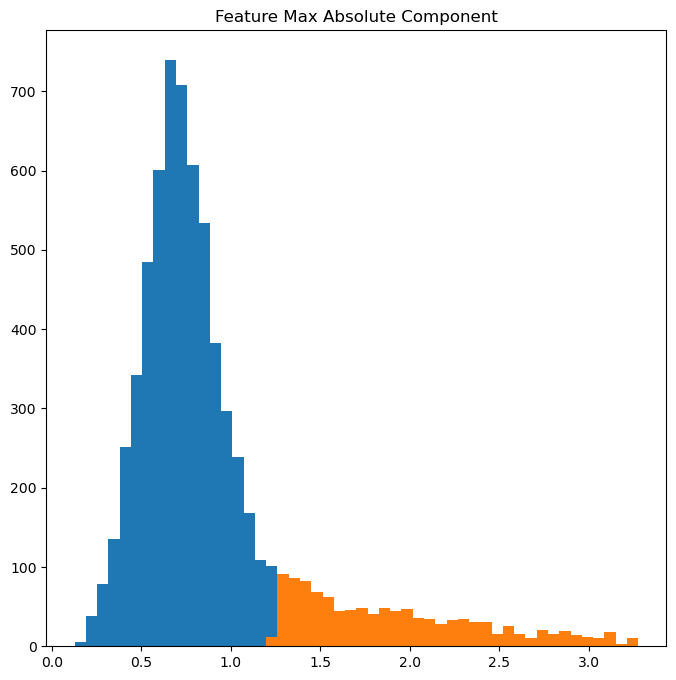

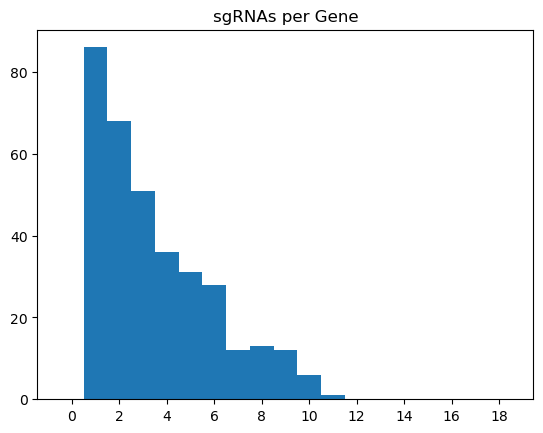

In [70]:
strong_effect_threshold = [1.,1.25,1.5][1]#[0]
# strong_effect_threshold = 1
n_neighbors = [5,10,15][1]

rootpath = HEADPATH+'/2025-08-12_lLAG8_12Hour_Analysis'
z_score_thr_dir = rootpath + "/Z_Score_Thr_" + str(strong_effect_threshold) + "_N_Neighbors_" + str(n_neighbors)
clustree_path = z_score_thr_dir + "/Clustree"
umap_path = z_score_thr_dir + "/UMAP"
compare_path = z_score_thr_dir + "/Comparison"

tr.writedir(z_score_thr_dir, overwrite=True)
tr.writedir(clustree_path, overwrite=True)
tr.writedir(umap_path, overwrite=True)

##current max
z_score_max_series = sgRNA_df_merged["Feature Max Absolute Component"]
min_v,max_v = np.min(z_score_max_series),np.percentile(z_score_max_series,99)
sgRNA_df_merged["Large Z-score"] = z_score_max_series>strong_effect_threshold
sgRNA_df_merged_filtered = sgRNA_df_merged[sgRNA_df_merged["Large Z-score"]]

jackknife_df["Large Z-score"] = jackknife_df["Feature Max Absolute Component"]>strong_effect_threshold
jackknife_df_filtered = jackknife_df[jackknife_df["Large Z-score"]]

plt.figure(figsize=(8,8))
plt.title("Feature Max Absolute Component")
plt.hist(sgRNA_df_merged[z_score_max_series<strong_effect_threshold]["Feature Max Absolute Component"].tolist(),bins=50,range=(min_v,max_v))
plt.hist(sgRNA_df_merged[z_score_max_series>=strong_effect_threshold]["Feature Max Absolute Component"].tolist(),bins=50,range=(min_v,max_v))
plt.show()

#include dropped genes
unique_genes, gene_counts = np.unique(sgRNA_df_merged_filtered["Gene"][sgRNA_df_merged_filtered["Gene"].apply(lambda x: type(x)==str)].tolist(), return_counts=True)
plt.title("sgRNAs per Gene")
plt.xticks(range(0,20,2),labels=range(0,20,2))
plt.hist(gene_counts,bins=np.arange(20)-0.5)
plt.show()

### Checking sgRNA Sampling Distribution

In [71]:
design_gene_list = np.unique(lDE20_design["Gene"][lDE20_design["Gene"].apply(lambda x: type(x)==str)].tolist()).tolist()
design_gene_names,design_count = np.unique(lDE20_design["Gene"][lDE20_design["Gene"].apply(lambda x: type(x)==str)].tolist(), return_counts=True)
design_gene_count_dict = dict(zip(design_gene_names,design_count))
design_gene_count_dict = {gene:(design_gene_count_dict[gene] if gene in design_gene_count_dict.keys() else 0) for gene in design_gene_list}
design_gene_count_list = list(design_gene_count_dict.values())

lDE20_nanopore_sgrna_only = lDE20_nanopore.groupby("opLAG1_id").apply(lambda x: x.iloc[0])
nanopore_gene_names,nanopore_count = np.unique(lDE20_nanopore_sgrna_only["Gene"][lDE20_nanopore_sgrna_only["Gene"].apply(lambda x: type(x)==str)].tolist(), return_counts=True)
nanopore_gene_count_dict = dict(zip(nanopore_gene_names,nanopore_count))
nanopore_gene_count_dict = {gene:(nanopore_gene_count_dict[gene] if gene in nanopore_gene_count_dict.keys() else 0) for gene in design_gene_list}
nanopore_gene_count_list = list(nanopore_gene_count_dict.values())

experiment_gene_names,experiment_count = np.unique(sgRNA_df_merged["Gene"][sgRNA_df_merged["Gene"].apply(lambda x: type(x)==str)].tolist(), return_counts=True)
experiment_gene_count_dict = dict(zip(experiment_gene_names,experiment_count))
experiment_gene_count_dict = {gene:(experiment_gene_count_dict[gene] if gene in experiment_gene_count_dict.keys() else 0) for gene in design_gene_list}
experiment_gene_count_list = list(experiment_gene_count_dict.values())

significant_gene_names,significant_count = np.unique(sgRNA_df_merged_filtered["Gene"][sgRNA_df_merged_filtered["Gene"].apply(lambda x: type(x)==str)].tolist(), return_counts=True)
significant_gene_count_dict = dict(zip(significant_gene_names,significant_count))
significant_gene_count_dict = {gene:(significant_gene_count_dict[gene] if gene in significant_gene_count_dict.keys() else 0) for gene in design_gene_list}
significant_gene_count_list = list(significant_gene_count_dict.values())

In [72]:
len(significant_gene_names)

344

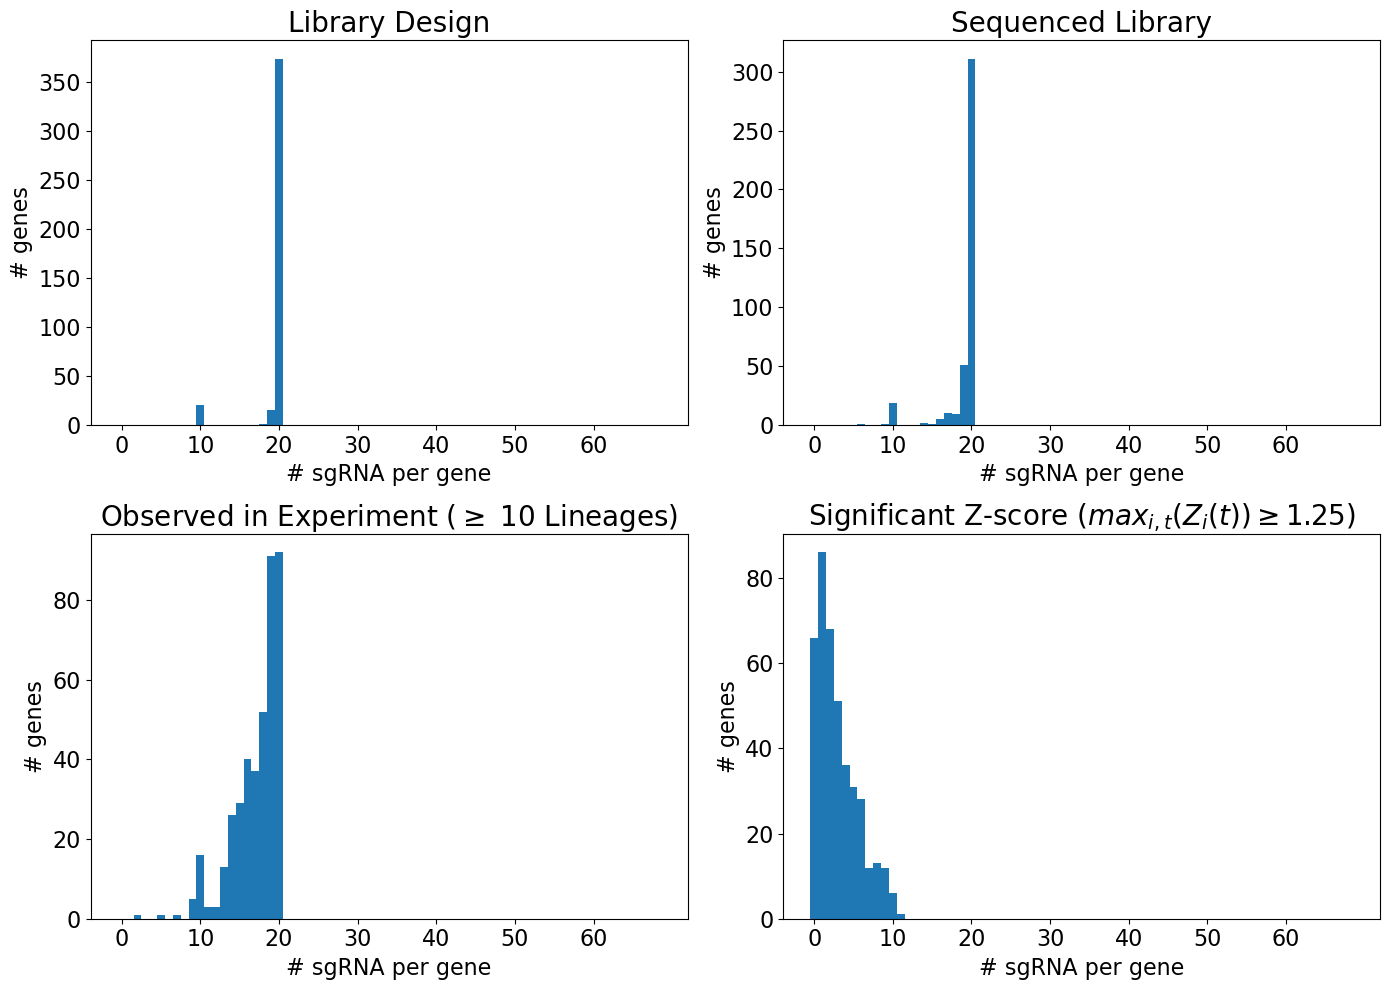

In [73]:
fig = plt.figure(figsize=(14,10))
plt.subplot(2, 2, 1)
plt.title("Library Design",fontsize=20)
plt.xticks(range(0,70,10),labels=range(0,70,10))
plt.xlabel("# sgRNA per gene",fontsize=16)
plt.xticks(fontsize=16)
plt.ylabel("# genes",fontsize=16)
plt.yticks(fontsize=16)
plt.hist(design_gene_count_list,bins=np.arange(70)-0.5)

plt.subplot(2, 2, 2)
plt.title("Sequenced Library",fontsize=20)
plt.xticks(range(0,70,10),labels=range(0,70,10))
plt.xlabel("# sgRNA per gene",fontsize=16)
plt.xticks(fontsize=16)
plt.ylabel("# genes",fontsize=16)
plt.yticks(fontsize=16)
plt.hist(nanopore_gene_count_list,bins=np.arange(70)-0.5)

plt.subplot(2, 2, 3)
plt.title("Observed in Experiment ($\geq$ 10 Lineages)",fontsize=20)
plt.xticks(range(0,70,10),labels=range(0,70,10))
plt.xlabel("# sgRNA per gene",fontsize=16)
plt.xticks(fontsize=16)
plt.ylabel("# genes",fontsize=16)
plt.yticks(fontsize=16)
plt.hist(experiment_gene_count_list,bins=np.arange(70)-0.5)

plt.subplot(2, 2, 4)
plt.title("Significant Z-score ($max_{i,t}(Z_{i}(t)) \geq " + str(strong_effect_threshold) + "$)",fontsize=20)
plt.xticks(range(0,70,10),labels=range(0,70,10))
plt.xlabel("# sgRNA per gene",fontsize=16)
plt.xticks(fontsize=16)
plt.ylabel("# genes",fontsize=16)
plt.yticks(fontsize=16)
plt.hist(significant_gene_count_list,bins=np.arange(70)-0.5)

plt.tight_layout()
fig.savefig(z_score_thr_dir + "/sgRNA_Frequencies.png",dpi=300)

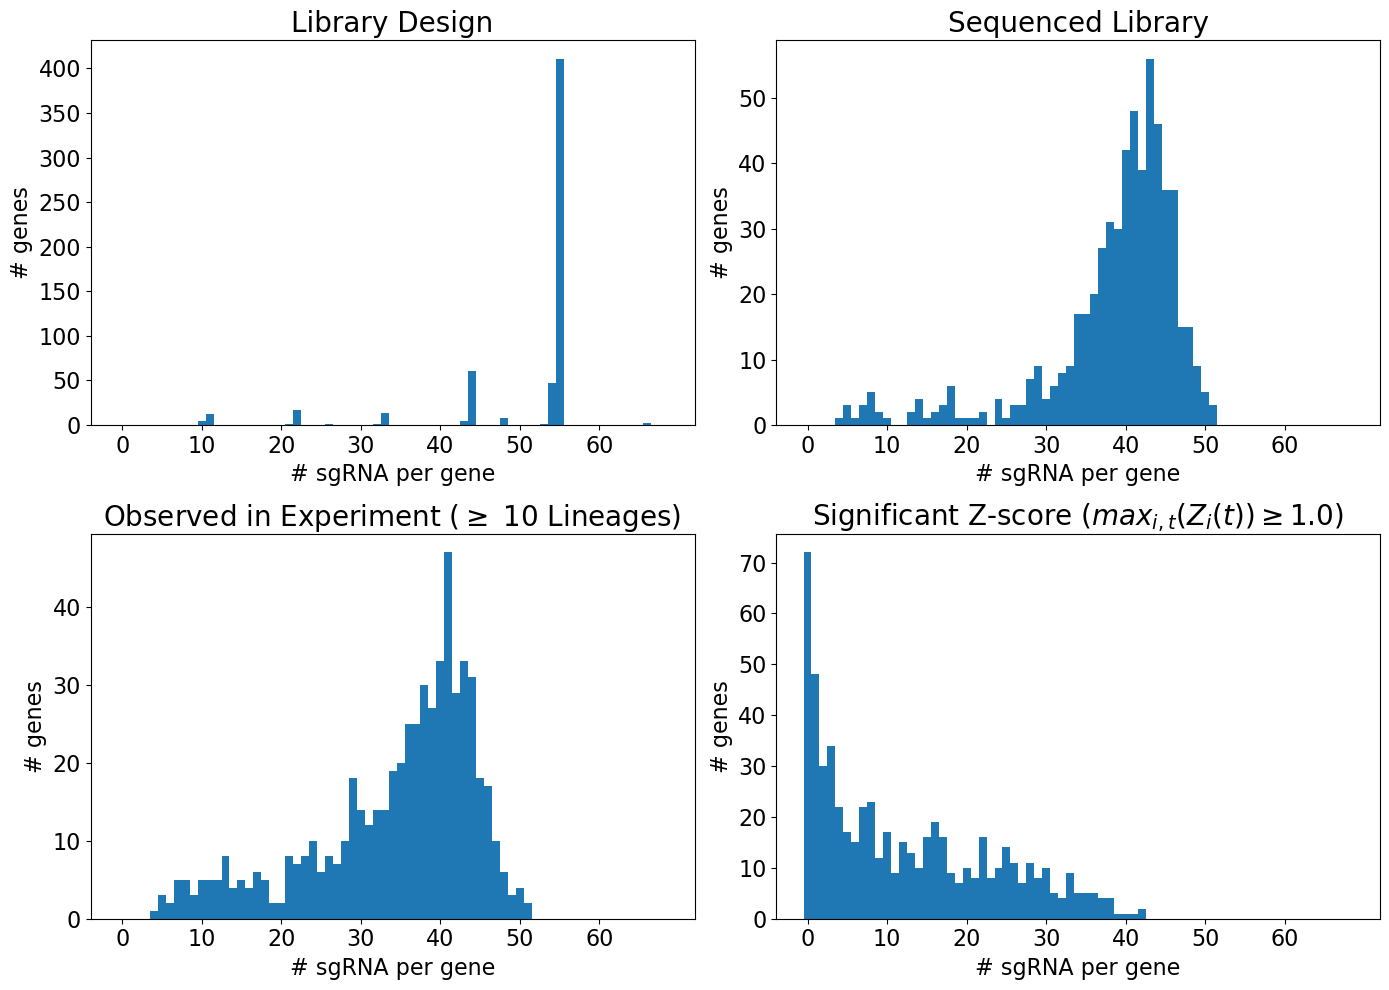

In [266]:
fig = plt.figure(figsize=(14,10))
plt.subplot(2, 2, 1)
plt.title("Library Design",fontsize=20)
plt.xticks(range(0,70,10),labels=range(0,70,10))
plt.xlabel("# sgRNA per gene",fontsize=16)
plt.xticks(fontsize=16)
plt.ylabel("# genes",fontsize=16)
plt.yticks(fontsize=16)
plt.hist(design_gene_count_list,bins=np.arange(70)-0.5)

plt.subplot(2, 2, 2)
plt.title("Sequenced Library",fontsize=20)
plt.xticks(range(0,70,10),labels=range(0,70,10))
plt.xlabel("# sgRNA per gene",fontsize=16)
plt.xticks(fontsize=16)
plt.ylabel("# genes",fontsize=16)
plt.yticks(fontsize=16)
plt.hist(nanopore_gene_count_list,bins=np.arange(70)-0.5)

plt.subplot(2, 2, 3)
plt.title("Observed in Experiment ($\geq$ 10 Lineages)",fontsize=20)
plt.xticks(range(0,70,10),labels=range(0,70,10))
plt.xlabel("# sgRNA per gene",fontsize=16)
plt.xticks(fontsize=16)
plt.ylabel("# genes",fontsize=16)
plt.yticks(fontsize=16)
plt.hist(experiment_gene_count_list,bins=np.arange(70)-0.5)

plt.subplot(2, 2, 4)
plt.title("Significant Z-score ($max_{i,t}(Z_{i}(t)) \geq " + str(strong_effect_threshold) + "$)",fontsize=20)
plt.xticks(range(0,70,10),labels=range(0,70,10))
plt.xlabel("# sgRNA per gene",fontsize=16)
plt.xticks(fontsize=16)
plt.ylabel("# genes",fontsize=16)
plt.yticks(fontsize=16)
plt.hist(significant_gene_count_list,bins=np.arange(70)-0.5)

plt.tight_layout()
fig.savefig(z_score_thr_dir + "/sgRNA_Frequencies.png",dpi=300)

### Computing Distance Matrix

In [74]:
### soft-DTW Calculation

X = np.array(sgRNA_df_merged_filtered["Feature Vector"].tolist())
X = np.swapaxes(X,1,2)
norm_soft_dtw_arr = parallel_norm_soft_dtw(X)

In [76]:
n_neighbors

10

In [75]:
jackknife_indices = list(jackknife_df_filtered.index.get_level_values(0).unique())

jackknife_norm_soft_dtw_arrs = []
jackknife_X_list = []

for jackknife_i in jackknife_indices:
    print("Jackknife: " + str(jackknife_i))
    jackknife_df_filtered_part = jackknife_df_filtered.loc[jackknife_i]
    jackknife_X = np.array(jackknife_df_filtered_part["Feature Vector"].tolist())
    jackknife_X = np.swapaxes(jackknife_X,1,2)
    jackknife_norm_soft_dtw_arr = parallel_norm_soft_dtw(jackknife_X)
    
    jackknife_norm_soft_dtw_arrs.append(jackknife_norm_soft_dtw_arr)
    jackknife_X_list.append(jackknife_X)

Jackknife: 0
Jackknife: 1
Jackknife: 2
Jackknife: 3
Jackknife: 4
Jackknife: 5
Jackknife: 6
Jackknife: 7
Jackknife: 8
Jackknife: 9


## Leiden Analysis

### Scanning Leiden Parameters

In [77]:
### Initialize Anndata Object
an_df_merged = anndata.AnnData(X=X.reshape(X.shape[0],-1),obs=sgRNA_df_merged_filtered) # AnnData container to use scanpy functions with unwrapped time vector

### Compute KNN Graph
n_pcs = 20 #This shouldn't affect anything

sc.pp.neighbors(an_df_merged, n_neighbors=n_neighbors, n_pcs=n_pcs)
knn_indices, knn_dists, forest = sc.neighbors.compute_neighbors_umap(norm_soft_dtw_arr, n_neighbors=n_neighbors, metric='precomputed' )
an_df_merged.uns["neighbors"]["distances"], an_df_merged.uns["neighbors"]["connectivities"] = sc.neighbors._compute_connectivities_umap(
    knn_indices,
    knn_dists,
    an_df_merged.shape[0],
    n_neighbors, # change to neighbors you plan to use
)
an_df_merged.obsp["distances"] = an_df_merged.uns["neighbors"]["distances"]
an_df_merged.obsp["connectivities"] = an_df_merged.uns["neighbors"]["connectivities"]
an_df_merged.obsp["soft_dtw"] = norm_soft_dtw_arr

         Falling back to preprocessing with `sc.pp.pca` and default params.


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/anndata/_core/anndata.py:183: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


#### Setup For Jackknife

In [78]:
an_df_merged_jackknife_list = []
for jackknife_i in jackknife_indices:
    jackknife_X = jackknife_X_list[jackknife_i]
    jackknife_df_filtered_part = jackknife_df_filtered.loc[jackknife_i]
    jackknife_norm_soft_dtw_arr = jackknife_norm_soft_dtw_arrs[jackknife_i]
    
    ### Initialize Anndata Object
    an_df_merged_jackknife = anndata.AnnData(X=jackknife_X.reshape(jackknife_X.shape[0],-1),\
                                             obs=jackknife_df_filtered_part) # AnnData container to use scanpy functions with unwrapped time vector
    ### Compute KNN Graph
    n_pcs = 20 #This shouldn't affect anything
    
    sc.pp.neighbors(an_df_merged_jackknife, n_neighbors=n_neighbors, n_pcs=n_pcs)
    knn_indices, knn_dists, forest = sc.neighbors.compute_neighbors_umap(jackknife_norm_soft_dtw_arr,\
                                                n_neighbors=n_neighbors, metric='precomputed' )
    an_df_merged_jackknife.uns["neighbors"]["distances"], an_df_merged_jackknife.uns["neighbors"]["connectivities"] = \
    sc.neighbors._compute_connectivities_umap(
        knn_indices,
        knn_dists,
        an_df_merged_jackknife.shape[0],
        n_neighbors, # change to neighbors you plan to use
    )
    an_df_merged_jackknife.obsp["distances"] = an_df_merged_jackknife.uns["neighbors"]["distances"]
    an_df_merged_jackknife.obsp["connectivities"] = an_df_merged_jackknife.uns["neighbors"]["connectivities"]
    an_df_merged_jackknife.obsp["soft_dtw"] = jackknife_norm_soft_dtw_arr
    an_df_merged_jackknife_list.append(an_df_merged_jackknife)

         Falling back to preprocessing with `sc.pp.pca` and default params.


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/anndata/_core/anndata.py:183: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


         Falling back to preprocessing with `sc.pp.pca` and default params.


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/anndata/_core/anndata.py:183: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


         Falling back to preprocessing with `sc.pp.pca` and default params.


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/anndata/_core/anndata.py:183: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


... (10 outputs left out)

         Falling back to preprocessing with `sc.pp.pca` and default params.


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/anndata/_core/anndata.py:183: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


         Falling back to preprocessing with `sc.pp.pca` and default params.


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/anndata/_core/anndata.py:183: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


### Clustering Metrics

- Silhouette Score - internal evaluation
- Adjusted Rand Index - external evaluation
    - TargetIDs could be used gainfully here
- Adjusted Mutual Information

In [79]:
max_val = 500.
min_val = 0.04
nsteps = 50

resolution_list = np.logspace(np.log10(min_val),np.log10(max_val),num=nsteps).tolist()

unique_targetids,targetid_counts = np.unique(an_df_merged.obs["TargetID"],return_counts=True)
non_singleton_targetids = unique_targetids[targetid_counts>1]

unique_genes,gene_counts = np.unique(an_df_merged.obs["Gene"],return_counts=True)
non_singleton_genes = unique_genes[gene_counts>1]

sil_score_list = []
targetid_rand_score_list = []
targetid_mut_info_score_list = []
targetid_homogeneity_list = []
targetid_completeness_list = []
targetid_v_measure_list = []

all_recall_target = []
mean_cluster_recall_target = []
max_cluster_recall_target = []
all_recall_gene = []
mean_cluster_recall_gene = []
max_cluster_recall_gene = []

gene_rand_score_list = []
gene_mut_info_score_list = []

for resolution in resolution_list:
    sc.tl.leiden(an_df_merged, resolution=resolution, n_iterations=-1)
    leiden_labels = an_df_merged.obs['leiden'].astype(int).tolist()
    targetid_labels = an_df_merged.obs['TargetID'].astype(int).tolist()
    
    an_df_merged_no_singleton = an_df_merged[an_df_merged.obs["TargetID"].isin(non_singleton_targetids)]
    leiden_labels_no_singleton = an_df_merged_no_singleton.obs["leiden"].astype(int).tolist()
    targetid_labels_no_singleton = an_df_merged_no_singleton.obs["TargetID"].astype(int).tolist()
    
    sil_score = skl.metrics.silhouette_score(norm_soft_dtw_arr, leiden_labels, metric='precomputed')
    sil_score_list.append(sil_score)
    
    targetid_rand_score = skl.metrics.adjusted_rand_score(targetid_labels_no_singleton, leiden_labels_no_singleton)
    targetid_mut_info_score = skl.metrics.adjusted_mutual_info_score(targetid_labels_no_singleton, leiden_labels_no_singleton)
    
    targetid_rand_score_list.append(targetid_rand_score)
    targetid_mut_info_score_list.append(targetid_mut_info_score)
    
    target_recall_df = get_recall_df(an_df_merged)
    gene_recall_df = get_recall_df(an_df_merged,recall_metric="Gene")
    
    all_recall_list_target = [val for lst in target_recall_df["TargetID_Recall_List_leiden"].tolist() for val in lst]
    mean_cluster_recall_list_target = target_recall_df["TargetID_Mean_Recall_leiden"].tolist()
    max_cluster_recall_list_target = target_recall_df["TargetID_Max_Recall_leiden"].tolist()
    
    all_recall_list_gene = [val for lst in gene_recall_df["Gene_Recall_List_leiden"].tolist() for val in lst]
    mean_cluster_recall_list_gene = gene_recall_df["Gene_Mean_Recall_leiden"].tolist()
    max_cluster_recall_list_gene = gene_recall_df["Gene_Max_Recall_leiden"].tolist()
    
    all_recall_target.append(all_recall_list_target)
    mean_cluster_recall_target.append(mean_cluster_recall_list_target)
    max_cluster_recall_target.append(max_cluster_recall_list_target)
    
    all_recall_gene.append(all_recall_list_gene)
    mean_cluster_recall_gene.append(mean_cluster_recall_list_gene)
    max_cluster_recall_gene.append(max_cluster_recall_list_gene)
    

    an_df_merged_no_singleton_genes = an_df_merged[an_df_merged.obs["Gene"].isin(non_singleton_genes)]
    leiden_labels_no_singleton_genes = an_df_merged_no_singleton_genes.obs["leiden"].astype(int).tolist()
    gene_labels_no_singleton_genes = an_df_merged_no_singleton_genes.obs["Gene"].astype(str).tolist()
    
    gene_rand_score = skl.metrics.adjusted_rand_score(gene_labels_no_singleton_genes, leiden_labels_no_singleton_genes)
    gene_mut_info_score = skl.metrics.adjusted_mutual_info_score(gene_labels_no_singleton_genes, leiden_labels_no_singleton_genes)
    gene_rand_score_list.append(gene_rand_score)
    gene_mut_info_score_list.append(gene_mut_info_score)

/tmp/ipykernel_1340946/2514561712.py:126: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  top_2_genes_series = an_df_copy.obs.groupby(cluster_label).apply(lambda x: "\n".join(get_top_genes(x["Gene"])))
/tmp/ipykernel_1340946/2514561712.py:132: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  recall_count_in_cluster = an_df_copy.obs.groupby(cluster_label).apply(lambda x: dict(zip(*np.unique(x[recall_metric],return_counts=True))))
/tmp/ipykernel_1340946/2514561712.py:133: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retai

#### Plotting Recall vs Resolution

In [80]:
output_target_recall_df = pd.DataFrame([[resolution_list[i],recall] for i,item in enumerate(all_recall_target) for recall in item],columns=["Resolution","Recall"])
output_gene_recall_df = pd.DataFrame([[resolution_list[i],recall] for i,item in enumerate(all_recall_gene) for recall in item],columns=["Resolution","Recall"])

output_target_mean_clster_recall_df = pd.DataFrame([[resolution_list[i],recall] for i,item in enumerate(mean_cluster_recall_target) for recall in item],columns=["Resolution","Recall"])
output_gene_mean_clster_recall_df = pd.DataFrame([[resolution_list[i],recall] for i,item in enumerate(mean_cluster_recall_gene) for recall in item],columns=["Resolution","Recall"])

output_target_max_clster_recall_df = pd.DataFrame([[resolution_list[i],recall] for i,item in enumerate(max_cluster_recall_target) for recall in item],columns=["Resolution","Recall"])
output_gene_max_clster_recall_df = pd.DataFrame([[resolution_list[i],recall] for i,item in enumerate(max_cluster_recall_gene) for recall in item],columns=["Resolution","Recall"])

/tmp/ipykernel_1340946/3301421828.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.lineplot(x="Resolution",y="Recall",data=output_target_recall_df, ci="sd",label="TargetID")
/tmp/ipykernel_1340946/3301421828.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.lineplot(x="Resolution",y="Recall",data=output_gene_recall_df, ci="sd",label="Gene")


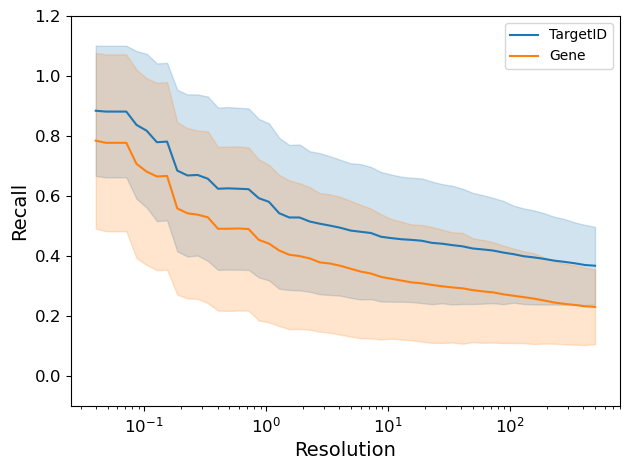

In [81]:
fig = plt.figure()
sns.lineplot(x="Resolution",y="Recall",data=output_target_recall_df, ci="sd",label="TargetID")
sns.lineplot(x="Resolution",y="Recall",data=output_gene_recall_df, ci="sd",label="Gene")
plt.ylim(-0.1,1.2)
plt.xscale("log")
plt.xlabel("Resolution",fontsize=14)
plt.ylabel("Recall",fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1340946/2283943436.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.lineplot(x="Resolution",y="Recall",data=output_target_mean_clster_recall_df, ci="sd",label="TargetID")
/tmp/ipykernel_1340946/2283943436.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.lineplot(x="Resolution",y="Recall",data=output_gene_mean_clster_recall_df, ci="sd",label="Gene")


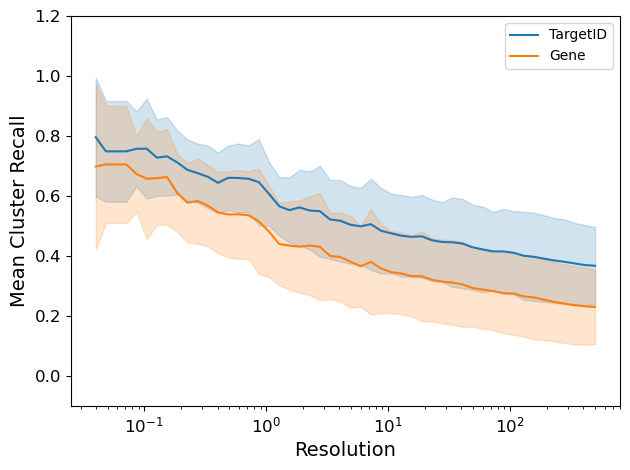

In [82]:
fig = plt.figure()
sns.lineplot(x="Resolution",y="Recall",data=output_target_mean_clster_recall_df, ci="sd",label="TargetID")
sns.lineplot(x="Resolution",y="Recall",data=output_gene_mean_clster_recall_df, ci="sd",label="Gene")
plt.ylim(-0.1,1.2)
plt.xscale("log")
plt.xlabel("Resolution",fontsize=14)
plt.ylabel("Mean Cluster Recall",fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1340946/3312265972.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.lineplot(x="Resolution",y="Recall",data=output_target_max_clster_recall_df, ci="sd",label="TargetID")
/tmp/ipykernel_1340946/3312265972.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.lineplot(x="Resolution",y="Recall",data=output_gene_max_clster_recall_df, ci="sd",label="Gene")


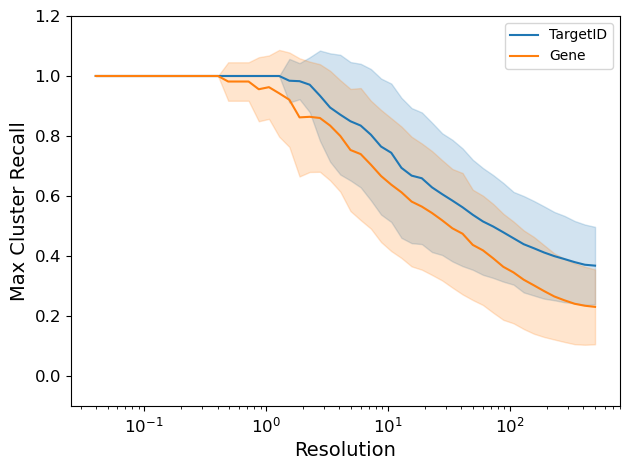

In [83]:
fig = plt.figure()
sns.lineplot(x="Resolution",y="Recall",data=output_target_max_clster_recall_df, ci="sd",label="TargetID")
sns.lineplot(x="Resolution",y="Recall",data=output_gene_max_clster_recall_df, ci="sd",label="Gene")
plt.ylim(-0.1,1.2)
plt.xscale("log")
plt.xlabel("Resolution",fontsize=14)
plt.ylabel("Max Cluster Recall",fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

#### Silhouette, Rand, and AMI vs Resolution (TargetID and Gene)

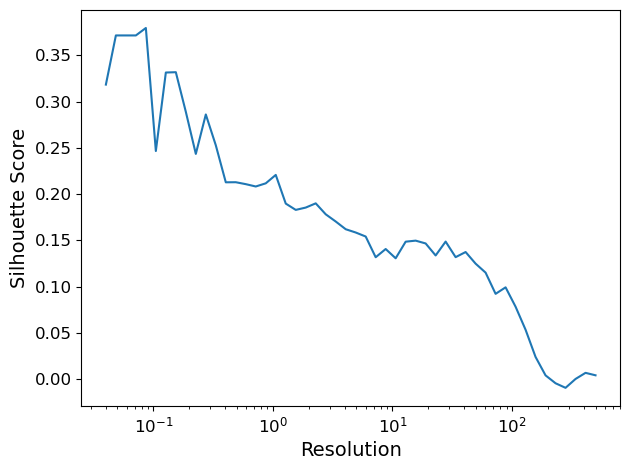

In [84]:
fig = plt.figure()
plt.plot(resolution_list,sil_score_list)
plt.xscale("log")
plt.xlabel("Resolution",fontsize=14)
plt.ylabel("Silhouette Score",fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

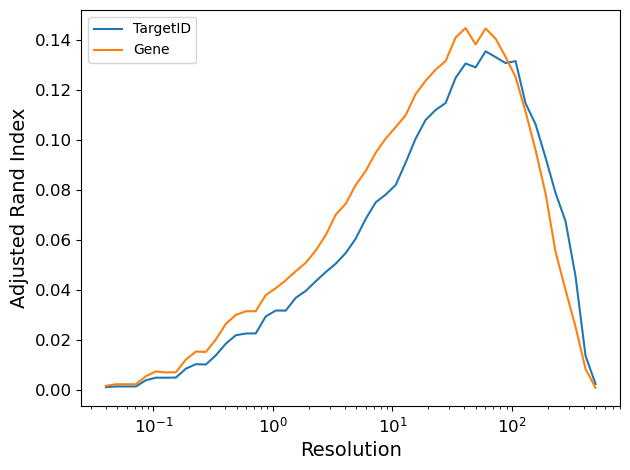

In [85]:
fig = plt.figure()
plt.plot(resolution_list,targetid_rand_score_list,label="TargetID")
plt.plot(resolution_list,gene_rand_score_list,label="Gene")
plt.xscale("log")
plt.xlabel("Resolution",fontsize=14)
plt.ylabel("Adjusted Rand Index",fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

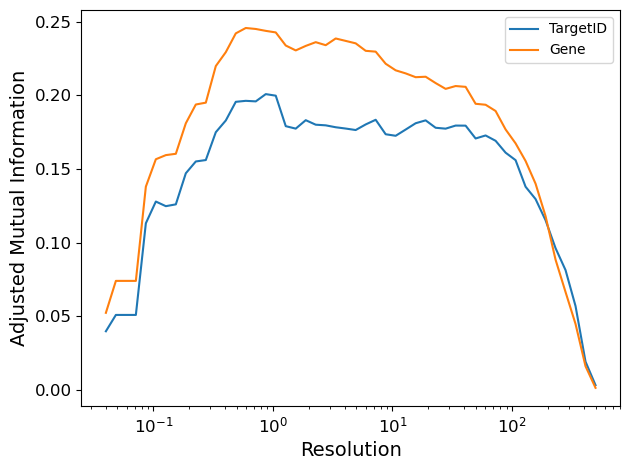

In [86]:
fig = plt.figure()
plt.plot(resolution_list,targetid_mut_info_score_list,label="TargetID")
plt.plot(resolution_list,gene_mut_info_score_list,label="Gene")
plt.xscale("log")
plt.xlabel("Resolution",fontsize=14)
plt.ylabel("Adjusted Mutual Information",fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

#### Setting Resolution Parameter Range and UMAP Projection

/tmp/ipykernel_1340946/2514561712.py:126: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  top_2_genes_series = an_df_copy.obs.groupby(cluster_label).apply(lambda x: "\n".join(get_top_genes(x["Gene"])))
/tmp/ipykernel_1340946/2514561712.py:132: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  recall_count_in_cluster = an_df_copy.obs.groupby(cluster_label).apply(lambda x: dict(zip(*np.unique(x[recall_metric],return_counts=True))))
/tmp/ipykernel_1340946/2514561712.py:133: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retai

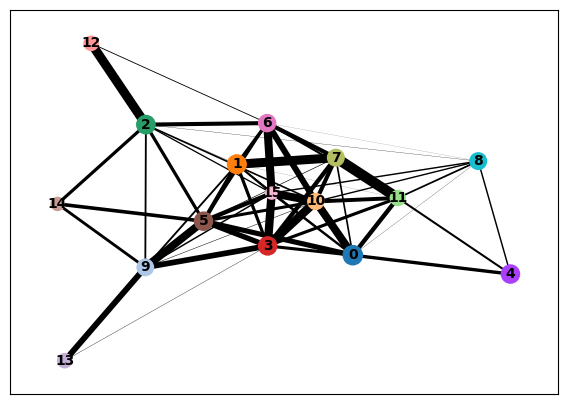

In [87]:
min_dist = 0.1
spread = 5.

an_df_clustree = copy.deepcopy(an_df_merged)
an_df_clustree.obs = an_df_clustree.obs.drop(labels=["leiden"],axis=1)

sil_score_list = []
resolution_list = [0.2,0.5,1.,2.]
for i,resolution in enumerate(resolution_list):
    sc.tl.leiden(an_df_clustree, resolution=resolution, n_iterations=-1, key_added="L" + str(i))
    leiden_labels = an_df_clustree.obs["L" + str(i)].astype(int).tolist()
    targetid_labels = an_df_clustree.obs['TargetID'].astype(int).tolist()
    
    target_recall_df = get_recall_df(an_df_clustree,cluster_label="L" + str(i))
    gene_recall_df = get_recall_df(an_df_clustree,recall_metric="Gene",cluster_label="L" + str(i))
    
    an_df_clustree.obs = an_df_clustree.obs.join(target_recall_df.drop(columns=["TargetID_Recall_List_L" + str(i)],axis=1),on="L" + str(i),how="left")
    an_df_clustree.obs = an_df_clustree.obs.join(gene_recall_df.drop(columns=["Gene_Recall_List_L" + str(i)],axis=1),on="L" + str(i),how="left")
    
## Add PAGA -> UMAP projection based on resolution of 2
sc.tl.paga(an_df_clustree, groups='L2')
sc.pl.paga(an_df_clustree, add_pos=True, show=False)
sc.tl.umap(an_df_clustree, init_pos='paga', min_dist = min_dist, spread=spread)

for jackknife_i in jackknife_indices:
    an_df_merged_jackknife = an_df_merged_jackknife_list[jackknife_i]
        
    sil_score_list = []
    resolution_list = [0.2,0.5,1.,2.]
    for i,resolution in enumerate(resolution_list):
        sc.tl.leiden(an_df_merged_jackknife, resolution=resolution, n_iterations=-1, key_added="L" + str(i))
    ##not sure if i need this reassign
    an_df_merged_jackknife_list[jackknife_i] = an_df_merged_jackknife

### Jackknife Cluster Stability

[1,
 14,
 15,
 18,
 19,
 27,
 32,
 37,
 47,
 48,
 57,
 58,
 59,
 71,
 74,
 78,
 95,
 110,
 118,
 154,
 176,
 177,
 184,
 193,
 196,
 208,
 210,
 215,
 216,
 217,
 237,
 249,
 285,
 296,
 310,
 315,
 318,
 326,
 347,
 348,
 351,
 352,
 353,
 372,
 376,
 377,
 388,
 389,
 390,
 391,
 393,
 397,
 398,
 426,
 431,
 432,
 438,
 455,
 471,
 472,
 493,
 496,
 508,
 516,
 526,
 537,
 556,
 563,
 564,
 565,
 567,
 569,
 571,
 578,
 580,
 582,
 584,
 585,
 587,
 588,
 590,
 596,
 598,
 602,
 609,
 610,
 614,
 616,
 628,
 631,
 632,
 636,
 639,
 644,
 649,
 651,
 652,
 654,
 655,
 656,
 660,
 674,
 685,
 688,
 691,
 693,
 694,
 696,
 697,
 704,
 705,
 706,
 714,
 716,
 724,
 729,
 730,
 732,
 733,
 734,
 741,
 743,
 744,
 747,
 748,
 750,
 752,
 754,
 756,
 759,
 764,
 766,
 769,
 784,
 786,
 790,
 795,
 796,
 799,
 803,
 805,
 806,
 807,
 808,
 809,
 812,
 814,
 822,
 829,
 833,
 834,
 840,
 844,
 845,
 847,
 849,
 851,
 852,
 853,
 861,
 865,
 868,
 869,
 870,
 873,
 874,
 883,
 887,
 890,
 892

In [99]:
shared_sgrnaids

['1',
 '14',
 '15',
 '18',
 '19',
 '27',
 '32',
 '37',
 '47',
 '48',
 '57',
 '58',
 '59',
 '71',
 '74',
 '78',
 '95',
 '110',
 '118',
 '154',
 '176',
 '177',
 '184',
 '193',
 '196',
 '208',
 '210',
 '215',
 '216',
 '217',
 '237',
 '249',
 '285',
 '296',
 '310',
 '315',
 '318',
 '326',
 '347',
 '348',
 '351',
 '352',
 '353',
 '372',
 '376',
 '377',
 '388',
 '389',
 '390',
 '391',
 '393',
 '397',
 '398',
 '426',
 '431',
 '432',
 '438',
 '455',
 '472',
 '496',
 '508',
 '526',
 '537',
 '556',
 '563',
 '564',
 '565',
 '567',
 '569',
 '571',
 '578',
 '580',
 '582',
 '584',
 '585',
 '587',
 '588',
 '590',
 '596',
 '598',
 '602',
 '609',
 '610',
 '614',
 '616',
 '628',
 '631',
 '632',
 '636',
 '639',
 '644',
 '649',
 '651',
 '652',
 '654',
 '655',
 '656',
 '660',
 '674',
 '685',
 '688',
 '691',
 '693',
 '694',
 '696',
 '697',
 '704',
 '705',
 '706',
 '714',
 '716',
 '724',
 '729',
 '730',
 '732',
 '733',
 '734',
 '741',
 '743',
 '744',
 '747',
 '748',
 '750',
 '752',
 '754',
 '756',
 '759',
 '

In [102]:
for resolution_idx in range(len(resolution_list)):
    cluster_level = "L" + str(resolution_idx)
    
    ARI_list = []
    jaccard_list = []
    recall_list = []
    intersection_list = []
    for jackknife_i in jackknife_indices:
        jackknife_clusters = an_df_merged_jackknife_list[jackknife_i].obs[cluster_level]
        # jackknife_sgrnaids = [int(eval(id)) for id in jackknife_clusters.index.unique().tolist()]
        # jackknife_sgrnaids = jackknife_clusters.index.unique().astype(int).tolist()
        jackknife_sgrnaids = jackknife_clusters.index.unique().tolist()
        
        true_sgrnaids = an_df_clustree.obs[cluster_level].index.unique().tolist()
        # true_sgrnaids = an_df_clustree.obs[cluster_level].index.unique().astype(int).tolist()
        # true_sgrnaids = [int(eval(id)) for id in an_df_clustree.obs[cluster_level].index.unique().tolist()]
        shared_sgrnaids = sorted(list(set(jackknife_sgrnaids)&set(true_sgrnaids)))
        shared_sgrnaids = [str(item) for item in shared_sgrnaids]
        
        clusters_i = an_df_clustree.obs[cluster_level].loc[shared_sgrnaids]
        clusters_j = jackknife_clusters.loc[shared_sgrnaids]
    
        ARI = skl.metrics.adjusted_rand_score(clusters_i,clusters_j)
        ARI_list.append(ARI) 
    
        main_cluster_list = clusters_i.unique()
        jaccard_score_dict = {}
        recall_score_dict = {}
        intersection_sgrna_dict = {}
        for main_cluster in main_cluster_list:
            clusters_i_single_cluster = (clusters_i==main_cluster)
            clusters_j_single_cluster_list = clusters_j[clusters_i_single_cluster].unique()
    
            jaccard_score_list = []
            recall_score_list = []
            intersection_sgrna_list = []
            for clusters_j_single_cluster in clusters_j_single_cluster_list:
                n_union = np.sum((clusters_j==clusters_j_single_cluster)|clusters_i_single_cluster)
                intersection_df = (clusters_j==clusters_j_single_cluster)&clusters_i_single_cluster
                intersection_sgrnaids = intersection_df[intersection_df].index.tolist()
                n_intersection = np.sum(intersection_df)
                jaccard_score = n_intersection/n_union
                recall_score = n_intersection/np.sum(clusters_i_single_cluster)
                
                jaccard_score_list.append(jaccard_score)
                recall_score_list.append(recall_score)
                intersection_sgrna_list.append(intersection_sgrnaids)
                
            jaccard_score_dict[main_cluster] = np.max(jaccard_score_list)
            recall_score_dict[main_cluster] = recall_score_list[np.argmax(jaccard_score_list)]
            intersection_sgrna_dict[main_cluster] = intersection_sgrna_list[np.argmax(jaccard_score_list)]
        
        jaccard_list.append(jaccard_score_dict)
        recall_list.append(recall_score_dict)
        intersection_list.append(intersection_sgrna_dict)
        
    mean_jaccard_score = {key:np.mean([item[key] for item in jaccard_list]) for key in jaccard_list[0].keys()}
    mean_jaccard_score = pd.Series(mean_jaccard_score)
    mean_jaccard_score.name=cluster_level + " Jackknife Jaccard"

    mean_recall_score = {key:np.mean([item[key] for item in recall_list]) for key in recall_list[0].keys()}
    mean_recall_score = pd.Series(mean_recall_score)
    mean_recall_score.name=cluster_level + " Jackknife Recall"
    
    agg_intersection = {key:[item[key] for item in intersection_list] for key in intersection_list[0].keys()}
    agg_intersection_flat= {key:[val for sublist in nested_list for val in sublist] for key,nested_list in agg_intersection.items()}
    # def get_recall_from_intersection(agg_intersection_flat,cluster_str,jackknife_ttl=len(jackknife_indices)):
    recall_output_df = []
    for main_cluster in main_cluster_list:
        true_sgrnaids = an_df_clustree.obs[cluster_level].index.unique().tolist()
        recall_dict = get_recall_from_intersection(agg_intersection_flat,main_cluster, jackknife_ttl=len(jackknife_indices))
        recall_output = {sgrnaid:recall_dict[sgrnaid] for sgrnaid in true_sgrnaids if sgrnaid in recall_dict.keys()}
        recall_output = pd.Series(recall_output)
        recall_output.name=cluster_level + " Jackknife sgRNA Recall"
        recall_output_df.append(recall_output)
    recall_output_df = pd.concat(recall_output_df, axis=0)
    
    an_df_clustree.obs = an_df_clustree.obs.join(mean_jaccard_score,on=cluster_level)
    an_df_clustree.obs = an_df_clustree.obs.join(mean_recall_score,on=cluster_level)
    an_df_clustree.obs = an_df_clustree.obs.join(recall_output_df,on="opLAG1_id")

### Per-Cluster Metrics Not Added Earlier

- Silhouette Score
- Top two genes in each cluster (for clustree)

In [ ]:
for i,resolution in enumerate(resolution_list):
    silhouette_sample_labels = skl.metrics.silhouette_samples(norm_soft_dtw_arr, an_df_clustree.obs["L" + str(i)], metric='precomputed')
    an_df_clustree.obs["Silhouette_Score_" + "L" + str(i)] = silhouette_sample_labels

    top_2_genes_series = an_df_clustree.obs.groupby("L" + str(i)).apply(lambda x: "\n".join(get_top_genes(x["Gene"])))
    top_2_genes_df = pd.DataFrame(top_2_genes_series).rename(columns={0:"Top_2_Genes_" + "L" + str(i)})
    top_2_genes_df_columns = top_2_genes_df.columns
    an_df_clustree_addition = an_df_clustree.obs[["L" + str(i)]].reset_index().merge(top_2_genes_df, on="L" + str(i)).set_index('opLAG1_id')
    an_df_clustree.obs[top_2_genes_df_columns] = an_df_clustree_addition[top_2_genes_df_columns]

## Export

#### Convert to R-friendly Format

In [107]:
import re

def convert_name_to_r(name,forbidden_characters=[":",")","(","-"]):
    name = name.replace(" ","_")
    for forbidden_character in forbidden_characters:
        name = name.replace(forbidden_character,"")
    return name

real_valued_labels = ['Mean: Delta time (hr)','Mean: Septum Displacement Length Normalized','Mean: Length',\
          'Mean: Width','Mean: mCherry mean_intensity','Mean: Instantaneous Growth Rate: Volume']
zscore_labels = ['Delta time (hr)','Septum Displacement Length Normalized','Length',\
          'Width','mCherry mean_intensity','Instantaneous Growth Rate: Volume']

non_real_valued_labels = [name+": Integrated Z-score" for name in zscore_labels]+\
                        [name+": Last Timepoint Z-score" for name in zscore_labels]+\
                        [name+": Max Absolute Z-score" for name in zscore_labels]+\
                        [name+": Max Magnitude Z-score" for name in zscore_labels]+\
                        [name+": Max Magnitude Minus Last Timepoint Z-score" for name in zscore_labels]

real_valued_labels_renamed = [convert_name_to_r(name) for name in real_valued_labels]
non_real_valued_labels_renamed = [convert_name_to_r(name) for name in non_real_valued_labels]

labels_of_interest = real_valued_labels + non_real_valued_labels
labels_of_interest_renamed = real_valued_labels_renamed+non_real_valued_labels_renamed

cluster_column_names = [column_name for column_name in an_df_clustree.obs.columns if re.fullmatch("L[0-9]{0,100}",column_name)!=None]
cluster_property_list = [column_name for column_name in an_df_clustree.obs.columns if re.search("_L[0-9]{0,100}",column_name)!=None]
columns_to_fetch = ["Gene"] + labels_of_interest + cluster_column_names + cluster_property_list

an_df_clustree_r_compat = copy.deepcopy(an_df_clustree)
an_df_clustree_r_compat.obs = an_df_clustree.obs[columns_to_fetch]
an_df_clustree_r_compat.obs = an_df_clustree_r_compat.obs.rename(columns=dict(zip(labels_of_interest,labels_of_interest_renamed)))
an_df_clustree_non_r_compat = copy.deepcopy(an_df_clustree_r_compat)

median_vals_dict = control_ss_mean_cv_df[real_valued_labels].median().to_dict()

for key in list(an_df_clustree_r_compat.uns.keys()):
    del an_df_clustree_r_compat.uns[key]
for key in list(an_df_clustree_r_compat.obsp.keys()):
    del an_df_clustree_r_compat.obsp[key]

an_df_clustree_r_compat = an_df_clustree_r_compat[~np.any(np.array(an_df_clustree_r_compat.obs[labels_of_interest_renamed].isna().values.tolist()),axis=1)]

### Cleaning Up Dataframe and Adding Back Original Data

In [113]:
columns_for_small_df = [
 'Kernel Trace: Delta time (s): Transformed: z score',
 'Kernel Trace: Septum Displacement Length Normalized: Transformed: z score',
 'Kernel Trace: Delta time (s)',
 'Kernel Trace: Septum Displacement',
 'Kernel Trace: Septum Displacement Length Normalized',
 'Kernel Trace: Length: Transformed: z score',
 'Kernel Trace: Width: Transformed: z score',
 'Kernel Trace: mCherry mean_intensity: Transformed: z score',
 'Kernel Trace: Length',
 'Kernel Trace: Width',
 'Kernel Trace: mCherry mean_intensity',
 'Kernel Trace: Instantaneous Growth Rate: Volume: Transformed: z score',
 'Kernel Trace: Instantaneous Growth Rate: Volume',
 'sgRNA',
 'Gene',
#  'N Mismatch',
 'Category',
 'TargetID',
 'N Observations',
 'Feature Vector',
 'Kernel Trace: Delta time (hr)',
 'Integrated Z-scores',
 'Last Timepoint Z-scores',
 'Delta time (hr): Integrated Z-score',
 'Delta time (hr): Last Timepoint Z-score',
 'Septum Displacement Length Normalized: Integrated Z-score',
 'Septum Displacement Length Normalized: Last Timepoint Z-score',
 'Length: Integrated Z-score',
 'Length: Last Timepoint Z-score',
 'Width: Integrated Z-score',
 'Width: Last Timepoint Z-score',
 'mCherry mean_intensity: Integrated Z-score',
 'mCherry mean_intensity: Last Timepoint Z-score',
 'Instantaneous Growth Rate: Volume: Integrated Z-score',
 'Instantaneous Growth Rate: Volume: Last Timepoint Z-score',
 'Integrated Z-scores',
 'Feature Max Magnitude Z-score',
 'Mean: Septum Displacement',
 'Mean: Septum Displacement Length Normalized',
 'Mean: Delta time (s)',
 'Mean: Length',
 'Mean: Width',
 'Mean: mCherry mean_intensity',
 'Mean: Instantaneous Growth Rate: Volume',
 'Mean: Delta time (hr)',
# 'Mean: GFP-Penta mean_intensity',
# 'Mean: GFP-Penta mean_intensity: Yeo-Johnson: z score',
 'L0',
 'L1',
 'L2',
 'L3',
 'Target Sequence',
#  'N Target Sites',
#  'Target Sites'
 ]

rename_column_dict = {'Kernel Trace: Delta time (s): Transformed: z score':'Interdivision Time (s) Z-score Timeseries',\
 'Kernel Trace: Septum Displacement Length Normalized: Transformed: z score':'Septum Displacement Length Normalized Z-score Timeseries',\
 'Kernel Trace: Delta time (s)':'Interdivision Time (s) Timeseries',\
 'Kernel Trace: Septum Displacement':'Septum Displacement (um) Timeseries',\
 'Kernel Trace: Septum Displacement Length Normalized':'Septum Displacement Length Normalized Timeseries',\
 'Kernel Trace: Length: Transformed: z score':'Length Z-score Timeseries',\
 'Kernel Trace: Width: Transformed: z score':'Width Z-score Timeseries',\
 'Kernel Trace: mCherry mean_intensity: Transformed: z score':'mKate2 Mean Intensity Z-score Timeseries',\
 'Kernel Trace: Length':'Length (um) Timeseries',\
 'Kernel Trace: Width':'Width (um) Timeseries',\
 'Kernel Trace: mCherry mean_intensity':'mKate2 Mean Intensity (AU) Timeseries',\
 'Kernel Trace: Instantaneous Growth Rate: Volume: Transformed: z score':'Volume Growth Rate Z-score Timeseries',\
 'Kernel Trace: Instantaneous Growth Rate: Volume':'Volume Growth Rate (1/hr) Timeseries',\
 'Kernel Trace: Delta time (hr)':'Interdivision Time (hr) Timeseries',\
 'Delta time (hr): Integrated Z-score':'Interdivision Time (hr) Integrated Z-score',\
 'Delta time (hr): Last Timepoint Z-score':'Interdivision Time (hr) Last Timepoint Z-score',\
 'Septum Displacement Length Normalized: Integrated Z-score':'Septum Displacement Length Normalized Integrated Z-score',\
 'Septum Displacement Length Normalized: Last Timepoint Z-score':'Septum Displacement Length Normalized Last Timepoint Z-score',\
 'Length: Integrated Z-score':'Length Integrated Z-score',\
 'Length: Last Timepoint Z-score':'Length Last Timepoint Z-score',\
 'Width: Integrated Z-score':'Width Integrated Z-score',\
 'Width: Last Timepoint Z-score':'Width Last Timepoint Z-score',\
 'mCherry mean_intensity: Integrated Z-score':'mKate2 Mean Intensity Integrated Z-score',\
 'mCherry mean_intensity: Last Timepoint Z-score':'mKate2 Mean Intensity Last Timepoint Z-score',\
 'Instantaneous Growth Rate: Volume: Integrated Z-score':'Volume Growth Rate Integrated Z-score',\
 'Instantaneous Growth Rate: Volume: Last Timepoint Z-score':'Volume Growth Rate Last Timepoint Z-score',\
 'Mean: Septum Displacement':'Mean Septum Displacement (um) Steady State',\
 'Mean: Septum Displacement Length Normalized':'Mean Septum Displacement Length Normalized Steady State',\
 'Mean: Delta time (s)':'Mean Interdivision Time (s) Steady State',\
 'Mean: Length':'Mean Length (um) Steady State',\
 'Mean: Width':'Mean Width (um) Steady State',\
 'Mean: mCherry mean_intensity':'Mean mKate2 Mean Intensity (AU) Steady State',\
 'Mean: Instantaneous Growth Rate: Volume':'Mean Volume Growth Rate (1/hr) Steady State',\
 'Mean: Delta time (hr)':'Mean Interdivision Time (hr) Steady State',\
 'Mean: GFP-Penta mean_intensity':'Mean GFP Mean Intensity (AU) (at $t_{f}$ for nucleoid snapshots)',\
 'Mean: GFP-Penta mean_intensity: Yeo-Johnson: z score':'Mean GFP Mean Intensity Z-score (at $t_{f}$ for nucleoid snapshots)'}

big_output_df = an_df_clustree.obs
big_output_df.index = an_df_clustree.obs.index.astype(float)
#stitch back on whole data
dropped_index = [idx for idx in sgRNA_df_merged.index if idx not in big_output_df.index]
dropped_df = sgRNA_df_merged.loc[dropped_index]
big_output_df = pd.concat([big_output_df,dropped_df]).sort_index()

# big_output_df = big_output_df.merge(lDE20_design[["Target Sequence","N Target Sites","Target Sites"]],how="left",left_on="oDEPool7_id",right_index=True)

small_output_df = big_output_df[columns_for_small_df]
small_output_df = small_output_df.rename(columns=rename_column_dict)

very_small_output_df = small_output_df.drop(columns=[name for name in small_output_df.columns if "Timeseries" in name]+["Feature Vector","Integrated Z-scores","Last Timepoint Z-scores","Feature Max Magnitude Z-score"])

### Save Clustree Dataframe - Only Pandas Dataframe (pickle and csv)

In [114]:
z_score_thr_dir

'/home/lag36/scratch/lag36/2025-06-03_lLAG8-10_Merged-Analysis/2025-06-04_lLAG8_ExpNum-Fixed//2025-08-12_lLAG8_12Hour_Analysis/Z_Score_Thr_1.25_N_Neighbors_10'

In [115]:
big_output_df.to_pickle(z_score_thr_dir+"/Pandas_Dataframe.pkl")
small_output_df.to_pickle(z_score_thr_dir+"/Pandas_Dataframe_Small.pkl")
very_small_output_df.to_pickle(z_score_thr_dir+"/Pandas_Dataframe_Very_Small.pkl")

big_output_df.to_csv(z_score_thr_dir+"/Pandas_Dataframe.csv")
small_output_df.to_csv(z_score_thr_dir+"/Pandas_Dataframe_Small.csv")
very_small_output_df.to_csv(z_score_thr_dir+"/Pandas_Dataframe_Very_Small.csv")

### Save Clustree R-compatible AnnData (hdf5)

In [203]:
an_df_clustree.obs[an_df_clustree.obs["Gene"]=="fusA"]["L3"]

opLAG1_id
639.0     1
644.0    19
649.0    11
651.0     7
652.0     7
654.0    23
655.0    11
656.0    23
Name: L3, dtype: object

In [207]:
np.unique(an_df_clustree.obs[an_df_clustree.obs["L3"]=="23"]["Gene"],return_counts=True)

(array(['acpS', 'cpgA', 'dfrA', 'fusA', 'gatC', 'gyrA', 'gyrB', 'leuS',
        'menE', 'murD', 'nadD', 'pdhC', 'pheA', 'polC', 'rpe', 'rplM',
        'rpsF', 'rpsG', 'rpsI', 'rpsL', 'rpsO', 'rpsP'], dtype=object),
 array([1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1]))

In [194]:
dask_controller.shutdown()

Done.


2025-08-12 12:48:44,765 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [235]:
def convert_categories_to_str(an_df_clustree):
    an_df_clustree_copy = an_df_clustree.copy()
    an_df_clustree_copy_df = pd.DataFrame(an_df_clustree_copy.obs)
    cols_category_dtype = [col for col in an_df_clustree_copy_df.columns if an_df_clustree_copy_df[col].dtype == 'category']
    for col in cols_category_dtype:
        an_df_clustree_copy_df[col] = an_df_clustree_copy_df[col].astype(str)
    an_df_clustree_copy.obs = an_df_clustree_copy_df
    return an_df_clustree_copy

an_df_clustree_r_compat_copy = convert_categories_to_str(an_df_clustree_r_compat)
an_df_clustree_non_r_compat_copy = convert_categories_to_str(an_df_clustree_non_r_compat)

an_df_clustree_r_compat_copy.write(z_score_thr_dir+"/AnnData.h5ad")
an_df_clustree_non_r_compat_copy.write(z_score_thr_dir+"/AnnData_nonRcompat.h5ad")

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/anndata/compat/__init__.py:298: FutureWarning: Moving element from .uns['neighbors']['distances'] to .obsp['distances'].

This is where adjacency matrices should go now.
  warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/anndata/compat/__init__.py:298: FutureWarning: Moving element from .uns['neighbors']['connectivities'] to .obsp['connectivities'].

This is where adjacency matrices should go now.
  warn(


In [81]:
dask_controller.shutdown()

Done.


2023-05-07 20:04:31,640 - distributed.client - ERROR - Failed to reconnect to scheduler after 30.00 seconds, closing client


In [ ]:
an_df_clustree_non_r_compat_copy

AnnData object with n_obs × n_vars = 1209 × 120
    obs: 'Gene', 'Mean_Delta_time_hr', 'Mean_Septum_Displacement_Length_Normalized', 'Mean_Length', 'Mean_Width', 'Mean_mCherry_mean_intensity', 'Mean_Instantaneous_Growth_Rate_Volume', 'Delta_time_hr_Integrated_Zscore', 'Septum_Displacement_Length_Normalized_Integrated_Zscore', 'Length_Integrated_Zscore', 'Width_Integrated_Zscore', 'mCherry_mean_intensity_Integrated_Zscore', 'Instantaneous_Growth_Rate_Volume_Integrated_Zscore', 'Delta_time_hr_Last_Timepoint_Zscore', 'Septum_Displacement_Length_Normalized_Last_Timepoint_Zscore', 'Length_Last_Timepoint_Zscore', 'Width_Last_Timepoint_Zscore', 'mCherry_mean_intensity_Last_Timepoint_Zscore', 'Instantaneous_Growth_Rate_Volume_Last_Timepoint_Zscore', 'Delta_time_hr_Max_Absolute_Zscore', 'Septum_Displacement_Length_Normalized_Max_Absolute_Zscore', 'Length_Max_Absolute_Zscore', 'Width_Max_Absolute_Zscore', 'mCherry_mean_intensity_Max_Absolute_Zscore', 'Instantaneous_Growth_Rate_Volume_Max_Absolut